# Practical Assignment 5: Ensemble Learning and Performance Evaluation

**Course:** Machine Learning  |  **Dataset:** Breast Cancer Wisconsin (Diagnostic) – built into scikit-learn  

### Objectives
1. Implement a **Stacking** ensemble with a meta-classifier.
2. Implement an **AdaBoost** ensemble with chosen base classifiers.
3. Implement a **Voting** ensemble (majority / hard voting, plus soft voting for comparison).
4. Compare ensembles against the individual base models using appropriate classification metrics.
5. Summarise findings, when to use each method, and future improvements.

## Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Base classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Ensembles
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded.")

Libraries loaded.


## 1. Dataset and Exploratory Analysis

The **Breast Cancer Wisconsin (Diagnostic)** dataset has 569 samples and 30 numeric features computed from digitised images of fine-needle aspirates of breast masses. The task is binary classification: **malignant (0)** vs **benign (1)**.

**Why this dataset?** It is a standard, clean, medium-sized benchmark where base models are strong but not perfect, so differences between ensembles are visible. It is also a high-stakes domain, where the choice of metric (especially recall for malignant cases) matters.

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Shape:", X.shape)
print("Classes:", dict(zip(data.target_names, [0, 1])))
print("\nClass distribution:")
print(y.value_counts().rename({0: "malignant", 1: "benign"}))
print("\nMissing values:", int(X.isna().sum().sum()))
X.head()

Shape: (569, 30)
Classes: {np.str_('malignant'): 0, np.str_('benign'): 1}

Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64

Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


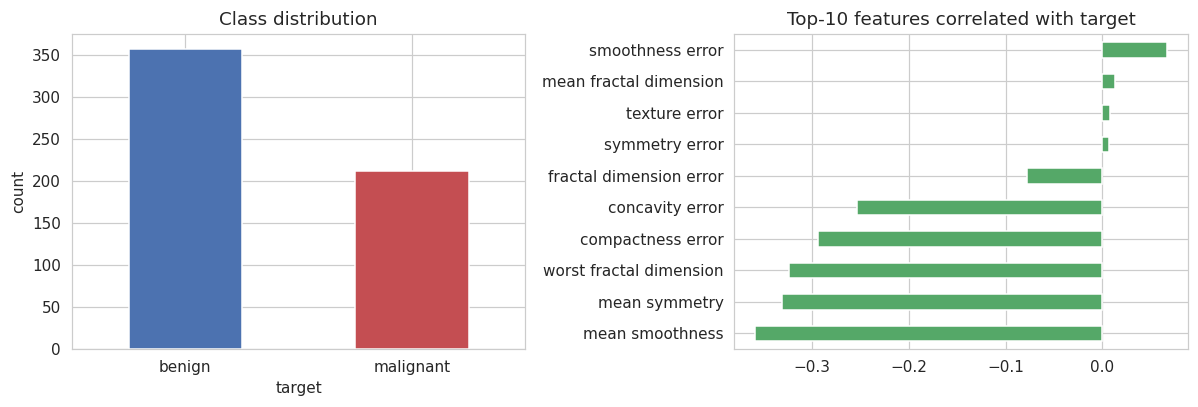

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
y.map({0: "malignant", 1: "benign"}).value_counts().plot(kind="bar", ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class distribution"); ax[0].set_ylabel("count"); ax[0].tick_params(axis="x", rotation=0)

corr = X.corrwith(y).sort_values()
corr.tail(10).plot(kind="barh", ax=ax[1], color="#55A868")
ax[1].set_title("Top-10 features correlated with target")
plt.tight_layout(); plt.show()

## 2. Train / Test Split

An 80/20 **stratified** split keeps the class ratio identical in both sets. The test set is used **only** for final evaluation. Scaling is placed *inside* pipelines so that it is fitted on training folds only (no data leakage).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test  class ratio:", y_test.value_counts(normalize=True).round(3).to_dict())

Train: (455, 30)  Test: (114, 30)
Train class ratio: {1: 0.626, 0: 0.374}
Test  class ratio: {1: 0.632, 0: 0.368}


## 3. Base Classifiers

Five **diverse** learners are chosen, because ensembles gain most when their members make *different* errors:

| Model | Family | Why included |
|---|---|---|
| Logistic Regression | linear, parametric | strong, well-calibrated baseline |
| K-Nearest Neighbours | instance-based | local, non-parametric decision boundary |
| SVM (RBF) | kernel method | flexible non-linear margin classifier |
| Decision Tree (depth 5) | rule-based | high variance, captures feature interactions |
| Gaussian Naive Bayes | probabilistic | very different inductive bias (feature independence) |

Distance/margin-based models (LR, KNN, SVM) are wrapped with `StandardScaler`.

In [5]:
base_models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "SVM (RBF)":           make_pipeline(StandardScaler(),
                                         SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
}
estimators = [(name, model) for name, model in base_models.items()]  # reused by Stacking / Voting
print("Base models:", list(base_models))

Base models: ['Logistic Regression', 'KNN', 'SVM (RBF)', 'Decision Tree', 'Naive Bayes']


## 4. Ensemble Models

### 4.1 Stacking (meta-classifier)
Base classifiers are trained on the data. Their **out-of-fold predicted probabilities** (5-fold, via `cv=5`) become the input features of a **meta-classifier** (Logistic Regression), which learns how to best combine them. Using out-of-fold predictions prevents the meta-learner from simply trusting base models that have overfit the training data.

In [6]:
stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1,
)
stacking.fit(X_train, y_train)
print("Stacking trained.")
print("Meta-learner coefficients (one per base model, positive-class probability):")
for (name, _), coef in zip(estimators, stacking.final_estimator_.coef_[0]):
    print(f"  {name:20s} {coef:+.3f}")

Stacking trained.
Meta-learner coefficients (one per base model, positive-class probability):
  Logistic Regression  +3.117
  KNN                  +1.980
  SVM (RBF)            +2.116
  Decision Tree        +0.845
  Naive Bayes          +0.459


### 4.2 AdaBoost
AdaBoost trains weak learners **sequentially**; after each round, misclassified samples receive higher weights so the next learner focuses on them. Final prediction = weighted vote of all learners.

Two different base classifiers are tried to show the effect of weak-learner strength:
* **Decision stump** (depth 1) – the classical weak learner
* **Shallow tree** (depth 3) – a slightly stronger learner

In [7]:
ada_stump = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)

ada_tree3 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)

ada_stump.fit(X_train, y_train)
ada_tree3.fit(X_train, y_train)
print("AdaBoost models trained.")

AdaBoost models trained.


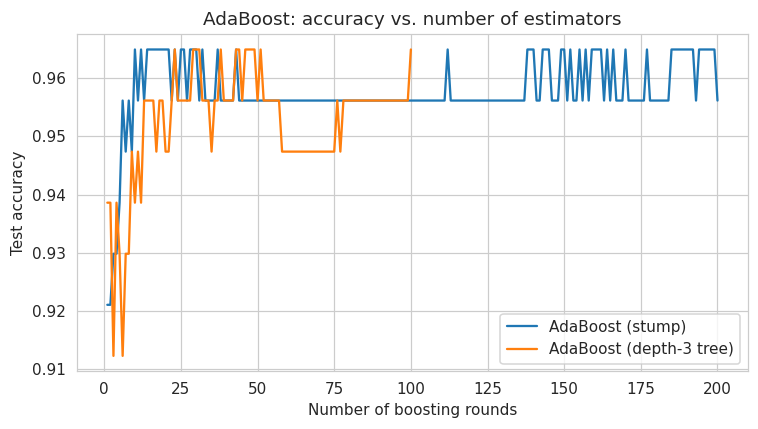

In [8]:
# How does test accuracy change as boosting rounds are added?
stump_curve = [accuracy_score(y_test, p) for p in ada_stump.staged_predict(X_test)]
tree3_curve = [accuracy_score(y_test, p) for p in ada_tree3.staged_predict(X_test)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(stump_curve) + 1), stump_curve, label="AdaBoost (stump)")
plt.plot(range(1, len(tree3_curve) + 1), tree3_curve, label="AdaBoost (depth-3 tree)")
plt.xlabel("Number of boosting rounds"); plt.ylabel("Test accuracy")
plt.title("AdaBoost: accuracy vs. number of estimators"); plt.legend(); plt.tight_layout(); plt.show()

### 4.3 Voting
* **Hard voting (majority voting)** – each base classifier casts one vote for a class; the class with the most votes wins. This is the method required by the assignment.
* **Soft voting** – averages predicted probabilities; added for comparison, since it uses confidence information.

In [9]:
voting_hard = VotingClassifier(estimators=estimators, voting="hard", n_jobs=-1)
voting_soft = VotingClassifier(estimators=estimators, voting="soft", n_jobs=-1)
voting_hard.fit(X_train, y_train)
voting_soft.fit(X_train, y_train)
print("Voting ensembles trained.")

# Show the majority vote mechanism explicitly on 8 test samples
votes = pd.DataFrame({name: m.predict(X_test) for name, m in voting_hard.named_estimators_.items()})
votes["Majority vote"] = voting_hard.predict(X_test)
votes["True label"] = y_test.values
votes.head(8)

Voting ensembles trained.


,Logistic Regression,KNN,SVM (RBF),Decision Tree,Naive Bayes,Majority vote,True label
0,0,0,0,0,0,0,0
1,1,1,1,1,1,1,1
2,0,0,0,0,0,0,0
3,1,1,1,1,1,1,1
4,0,0,0,0,0,0,0
5,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1
7,0,0,0,0,0,0,0


## 5. Performance Evaluation

**Metrics used and why**
* **Accuracy** – overall correctness (fine here because classes are only mildly imbalanced, 63/37).
* **Precision** – of samples predicted benign, how many truly are.
* **Recall** – of truly benign samples, how many were found.
* **F1-score** – harmonic mean of precision and recall.
* **ROC-AUC** – threshold-independent ranking quality.
* **Confusion matrix** – the clinically important error counts. A *false positive* here (a malignant tumour predicted benign) is the costly mistake.

We also report **5-fold cross-validated accuracy** on the training set to check that the single test split is not misleading.

In [10]:
all_models = {**base_models,
              "Stacking (LR meta)":      stacking,
              "AdaBoost (stump)":        ada_stump,
              "AdaBoost (depth-3 tree)": ada_tree3,
              "Voting (hard / majority)": voting_hard,
              "Voting (soft)":           voting_soft}
ensemble_names = ["Stacking (LR meta)", "AdaBoost (stump)", "AdaBoost (depth-3 tree)",
                  "Voting (hard / majority)", "Voting (soft)"]

def get_scores(model, X_):
    if hasattr(model, "predict_proba"):
        try:
            return model.predict_proba(X_)[:, 1]
        except Exception:
            pass
    return model.decision_function(X_)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, preds = [], {}
for name, model in all_models.items():
    if name not in ["Stacking (LR meta)", "AdaBoost (stump)", "AdaBoost (depth-3 tree)",
                    "Voting (hard / majority)", "Voting (soft)"]:
        model.fit(X_train, y_train)          # base models (ensembles already fitted)
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    auc = np.nan
    if name != "Voting (hard / majority)":   # hard voting has no probabilities
        auc = roc_auc_score(y_test, get_scores(model, X_test))
    rows.append({
        "Model": name,
        "Type": "Ensemble" if name in ensemble_names else "Base",
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
        "ROC-AUC":   auc,
        "CV Acc (mean)": cv_scores.mean(),
        "CV Acc (std)":  cv_scores.std(),
    })

results = pd.DataFrame(rows).set_index("Model")
results_sorted = results.sort_values(["F1-score", "Accuracy"], ascending=False)
results_sorted.round(4)

,Type,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV Acc (mean),CV Acc (std)
Model,,,,,,,,
Logistic Regression,Base,0.9825,0.9861,0.9861,0.9861,0.9954,0.9780,0.0098
SVM (RBF),Base,0.9825,0.9861,0.9861,0.9861,0.9950,0.9692,0.0146
KNN,Base,0.9737,0.9600,1.0000,0.9796,0.9884,0.9626,0.0204
Voting (soft),Ensemble,0.9737,0.9600,1.0000,0.9796,0.9927,0.9670,0.0155
Stacking (LR meta),Ensemble,0.9737,0.9726,0.9861,0.9793,0.9947,0.9736,0.0149
Voting (hard / majority),Ensemble,0.9737,0.9726,0.9861,0.9793,NaN,0.9758,0.0108
AdaBoost (depth-3 tree),Ensemble,0.9649,0.9595,0.9861,0.9726,0.9907,0.9758,0.0108
AdaBoost (stump),Ensemble,0.9561,0.9467,0.9861,0.9660,0.9848,0.9692,0.0146
Naive Bayes,Base,0.9386,0.9452,0.9583,0.9517,0.9878,0.9407,0.0247


In [11]:
# Highlighted version of the table
(results_sorted.round(4).style
    .background_gradient(cmap="Greens", subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "CV Acc (mean)"])
    .format(precision=4))

,Type,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV Acc (mean),CV Acc (std)
Model,,,,,,,,
Logistic Regression,Base,0.9825,0.9861,0.9861,0.9861,0.9954,0.9780,0.0098
SVM (RBF),Base,0.9825,0.9861,0.9861,0.9861,0.9950,0.9692,0.0146
KNN,Base,0.9737,0.9600,1.0000,0.9796,0.9884,0.9626,0.0204
Voting (soft),Ensemble,0.9737,0.9600,1.0000,0.9796,0.9927,0.9670,0.0155
Stacking (LR meta),Ensemble,0.9737,0.9726,0.9861,0.9793,0.9947,0.9736,0.0149
Voting (hard / majority),Ensemble,0.9737,0.9726,0.9861,0.9793,nan,0.9758,0.0108
AdaBoost (depth-3 tree),Ensemble,0.9649,0.9595,0.9861,0.9726,0.9907,0.9758,0.0108
AdaBoost (stump),Ensemble,0.9561,0.9467,0.9861,0.9660,0.9848,0.9692,0.0146
Naive Bayes,Base,0.9386,0.9452,0.9583,0.9517,0.9878,0.9407,0.0247


### 5.1 Visual comparison

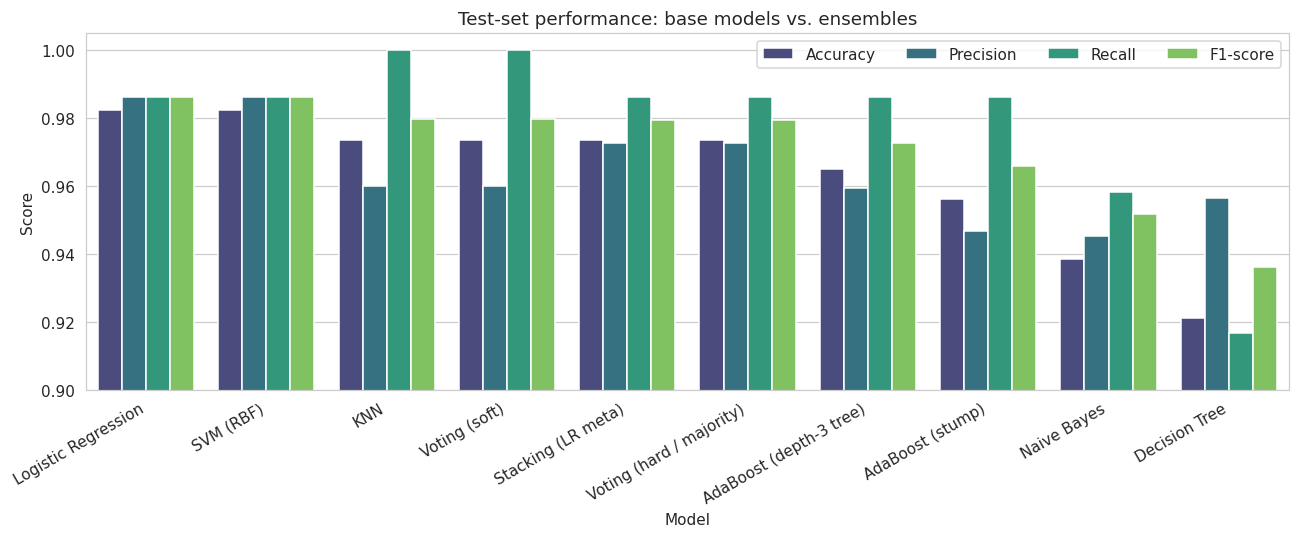

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_sorted[metrics].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
plt.ylim(0.90, 1.005)
plt.xticks(rotation=30, ha="right")
plt.title("Test-set performance: base models vs. ensembles")
plt.legend(loc="upper right", ncol=4)
plt.tight_layout(); plt.show()

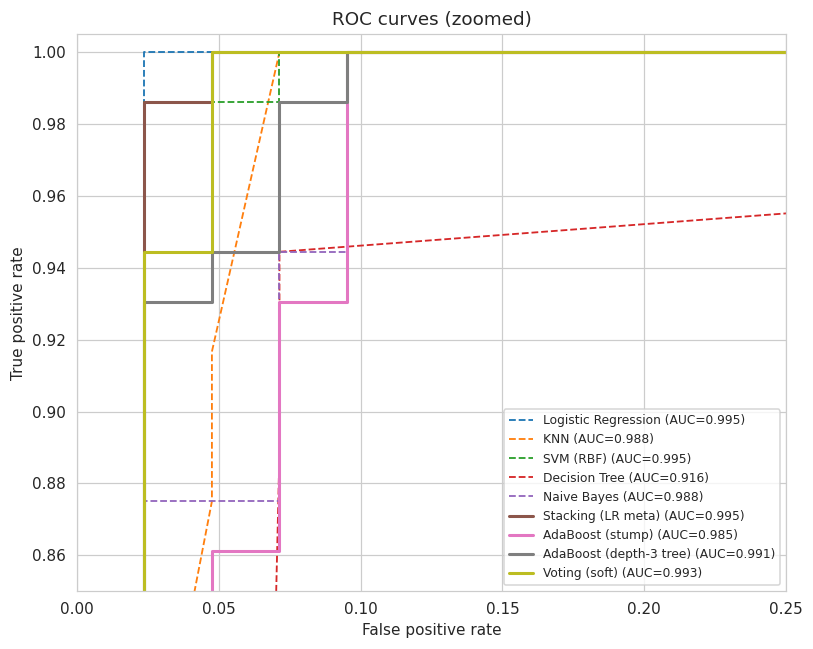

In [13]:
# ROC curves (hard voting excluded: it has no probability scores)
plt.figure(figsize=(7.5, 6))
for name, model in all_models.items():
    if name == "Voting (hard / majority)":
        continue
    fpr, tpr, _ = roc_curve(y_test, get_scores(model, X_test))
    style = "-" if name in ensemble_names else "--"
    plt.plot(fpr, tpr, style, lw=2 if name in ensemble_names else 1.2,
             label=f"{name} (AUC={roc_auc_score(y_test, get_scores(model, X_test)):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=1)
plt.xlim(0, 0.25); plt.ylim(0.85, 1.005)   # zoom in on the top-left corner
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (zoomed)"); plt.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

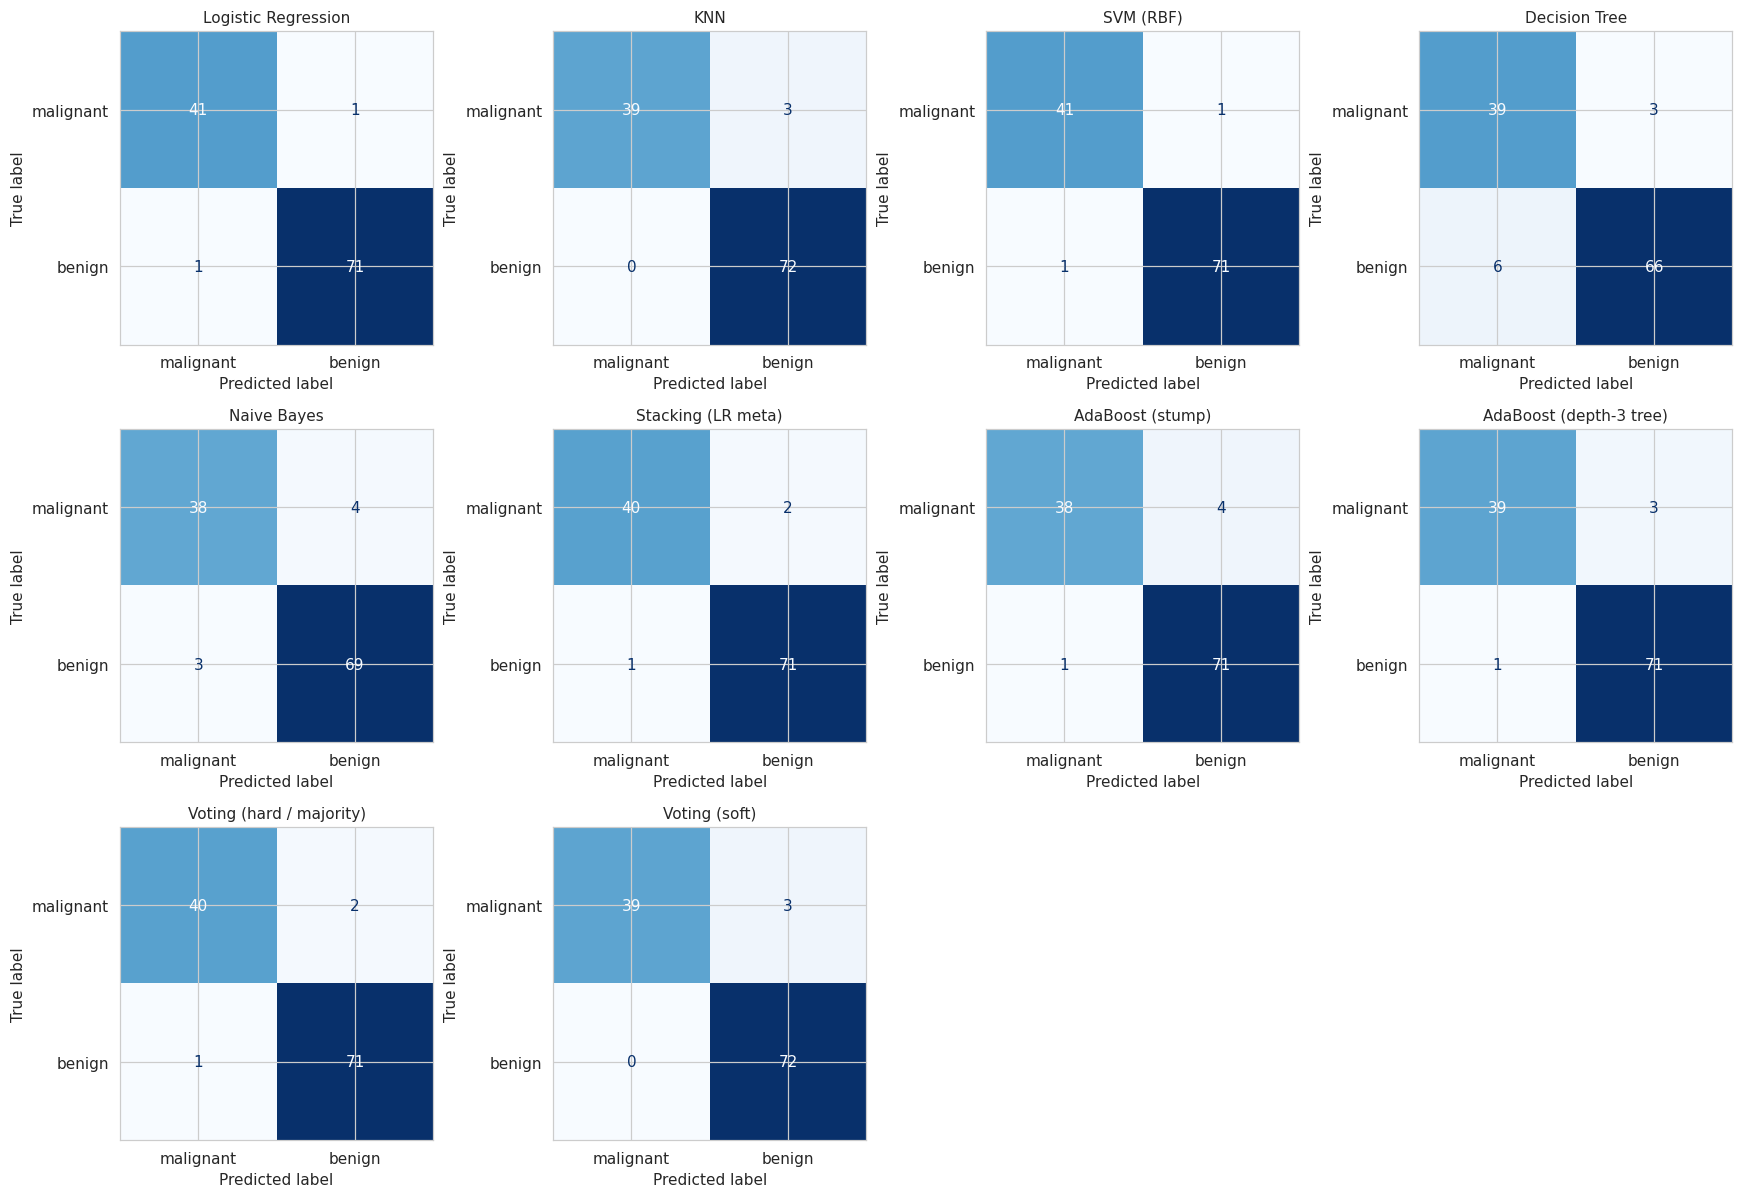

Malignant cases missed (predicted benign) out of 42 malignant in test set:
  Logistic Regression        1
  SVM (RBF)                  1
  Stacking (LR meta)         2
  Voting (hard / majority)   2
  KNN                        3
  Decision Tree              3
  AdaBoost (depth-3 tree)    3
  Voting (soft)              3
  Naive Bayes                4
  AdaBoost (stump)           4


In [14]:
# Confusion matrices for all models
n = len(all_models)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

# Costly error: malignant tumour predicted as benign
fn = {name: int(((y_test == 0) & (p == 1)).sum()) for name, p in preds.items()}
print("Malignant cases missed (predicted benign) out of", int((y_test == 0).sum()), "malignant in test set:")
for k, v in sorted(fn.items(), key=lambda kv: kv[1]):
    print(f"  {k:26s} {v}")

In [15]:
print(classification_report(y_test, preds[results_sorted.index[0]],
                            target_names=["malignant", "benign"], digits=4))
print("^ Report for best model by F1:", results_sorted.index[0])

              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

^ Report for best model by F1: Logistic Regression


### 5.2 Robust comparison: repeated cross-validation on the full dataset
A single 114-sample test set is small (one error ≈ 0.9 % accuracy), so differences of one or two samples are within noise. We therefore repeat stratified 5-fold CV **3 times** (15 scores per model) on all 569 samples and look at the distribution.

,Mean accuracy,Std
Logistic Regression,0.9760,0.0131
SVM (RBF),0.9760,0.0143
Voting (hard / majority),0.9748,0.0141
Stacking (LR meta),0.9742,0.0108
KNN,0.9672,0.0143
AdaBoost (depth-3 tree),0.9660,0.0132
AdaBoost (stump),0.9660,0.0179
Voting (soft),0.9642,0.0151
Naive Bayes,0.9385,0.0178
Decision Tree,0.9332,0.0241


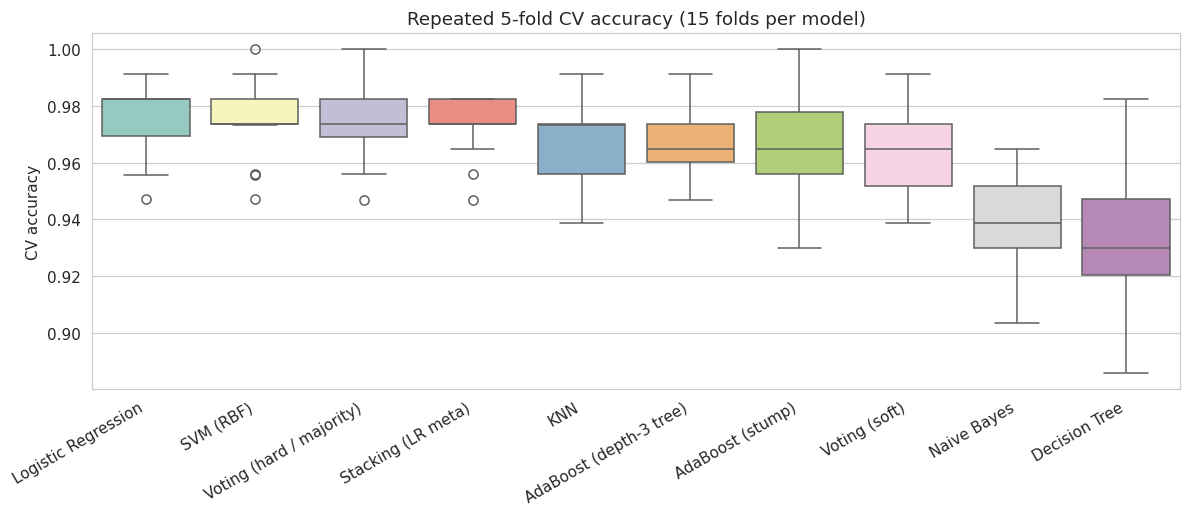

In [16]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_results = {}
for name, model in all_models.items():
    cv_results[name] = cross_val_score(model, X, y, cv=rcv, scoring="accuracy", n_jobs=-1)

cv_df = pd.DataFrame(cv_results)
summary = pd.DataFrame({"Mean accuracy": cv_df.mean(), "Std": cv_df.std()}).sort_values("Mean accuracy", ascending=False)
display(summary.round(4))

order = summary.index
plt.figure(figsize=(11, 4.8))
sns.boxplot(data=cv_df[order], palette="Set3")
plt.xticks(rotation=30, ha="right"); plt.ylabel("CV accuracy")
plt.title("Repeated 5-fold CV accuracy (15 folds per model)")
plt.tight_layout(); plt.show()

### 5.3 Why do ensembles help? Diversity of the base models
Ensembles only improve on their members when the members' errors are *not identical*. The matrix below shows the fraction of test samples on which each pair of base models **disagree**.

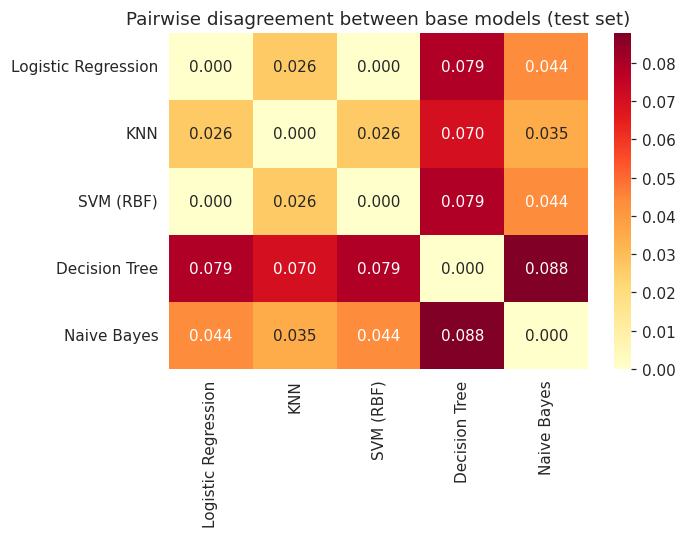

In [17]:
base_names = list(base_models)
dis = pd.DataFrame(index=base_names, columns=base_names, dtype=float)
for a in base_names:
    for b in base_names:
        dis.loc[a, b] = np.mean(preds[a] != preds[b])
plt.figure(figsize=(6.5, 5))
sns.heatmap(dis.astype(float), annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Pairwise disagreement between base models (test set)")
plt.tight_layout(); plt.show()

### 5.4 Interpretability: which features does AdaBoost rely on?

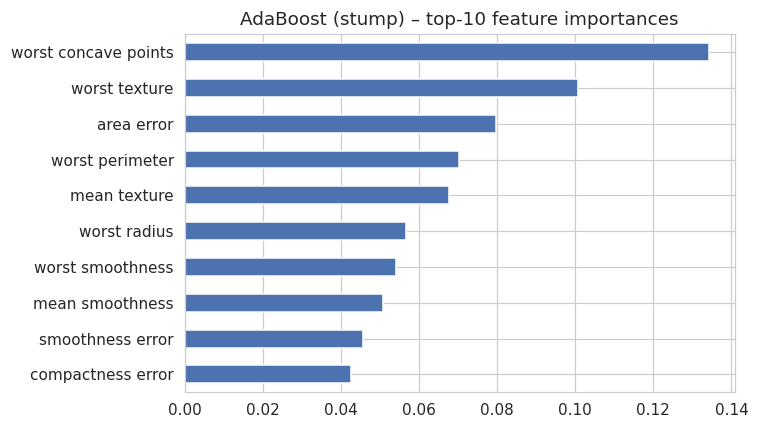

In [18]:
imp = pd.Series(ada_stump.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 4))
imp[::-1].plot(kind="barh", color="#4C72B0")
plt.title("AdaBoost (stump) – top-10 feature importances"); plt.tight_layout(); plt.show()

## 6. Auto-generated summary of results

In [19]:
best_test = results_sorted.index[0]
best_cv = summary.index[0]
best_base = results[results["Type"] == "Base"].sort_values(["F1-score", "Accuracy"], ascending=False).index[0]
best_ens = results[results["Type"] == "Ensemble"].sort_values(["F1-score", "Accuracy"], ascending=False).index[0]

print(f"Best model on the hold-out test set (by F1)   : {best_test}")
print(f"Best base model on test set                    : {best_base}  "
      f"(Acc={results.loc[best_base,'Accuracy']:.4f}, F1={results.loc[best_base,'F1-score']:.4f})")
print(f"Best ensemble on test set                      : {best_ens}  "
      f"(Acc={results.loc[best_ens,'Accuracy']:.4f}, F1={results.loc[best_ens,'F1-score']:.4f})")
print(f"Best model by repeated 5-fold CV on full data  : {best_cv}  "
      f"(mean acc={summary.loc[best_cv,'Mean accuracy']:.4f})")

Best model on the hold-out test set (by F1)   : Logistic Regression
Best base model on test set                    : Logistic Regression  (Acc=0.9825, F1=0.9861)
Best ensemble on test set                      : Voting (soft)  (Acc=0.9737, F1=0.9796)
Best model by repeated 5-fold CV on full data  : Logistic Regression  (mean acc=0.9760)


## 7. Findings, Insights and Future Work

### 7.1 What the results show (random_state = 42, 114 test samples)

| Model | Accuracy | F1 | Malignant missed (of 42) | Repeated-CV accuracy |
|---|---|---|---|---|
| Logistic Regression | 0.9825 | 0.9861 | 1 | 0.9760 |
| SVM (RBF) | 0.9825 | 0.9861 | 1 | 0.9760 |
| Voting (hard / majority) | 0.9737 | 0.9793 | 2 | 0.9748 |
| Stacking (LR meta) | 0.9737 | 0.9793 | 2 | 0.9742 |
| Voting (soft) | 0.9737 | 0.9796 | 3 | 0.9642 |
| KNN | 0.9737 | 0.9796 | 3 | 0.9672 |
| AdaBoost (depth-3 tree) | 0.9649 | 0.9726 | 3 | 0.9660 |
| AdaBoost (stump) | 0.9561 | 0.9660 | 4 | 0.9660 |
| Naive Bayes | 0.9386 | 0.9517 | 4 | 0.9385 |
| Decision Tree | 0.9211 | 0.9362 | 3 | 0.9332 |

1. **Every ensemble beat the weakest base learners.** The single Decision Tree (92.1 %) and Naive Bayes (93.9 %) were clearly improved on by all five ensembles (95.6 % – 97.4 %).
2. **No ensemble beat the best single base model on this dataset.** Logistic Regression and SVM scored 1–2 test samples better than the ensembles. With only 114 test samples, one sample ≈ 0.9 % accuracy, and the repeated-CV results (std ≈ 0.013) show the top models are statistically indistinguishable. The honest conclusion is *“ensembles matched, but did not clearly surpass, the best strong base model”*.
3. **Reason:** this dataset is almost linearly separable, so Logistic Regression is already close to the ceiling. LR and SVM disagreed on 0 % of test samples, and the diversity matrix shows the strong models disagree little with each other (2.6 – 4.4 %). Ensembles need *diverse* errors to gain; the only diverse members (Decision Tree, Naive Bayes) were also the weakest.
4. **Stacking** learned to trust the strong models: its meta-learner gave the largest weights to Logistic Regression (+3.12), SVM (+2.12) and KNN (+1.98), and much smaller ones to Decision Tree (+0.85) and Naive Bayes (+0.46). It was therefore robust against its weak members, whereas equal-weight **soft voting** was pulled down by them (repeated-CV 0.964 vs 0.975 for hard voting).
5. **AdaBoost** turned very weak learners into a competitive classifier: stumps reached 95.6 % and depth-3 trees 96.5 %, far above a single Decision Tree (92.1 %). Stronger weak learners helped, and the staged-accuracy curve shows most of the gain arrives within the first ~10–25 rounds, after which test accuracy plateaus and only fluctuates by a sample or two, so 200 rounds were more than needed on this dataset.
6. **Clinical view:** since a malignant tumour predicted benign is the costly error, the count of missed malignant cases matters more than accuracy alone. LR/SVM missed 1, stacking and hard voting 2, and the others 3–4 of 42.

### 7.2 When to use each method

| Method | Use when | Watch out for |
|---|---|---|
| **Voting (hard)** | You already have several reasonably good, *different* models and want a simple, cheap, robust combination | Weak members get an equal vote; needs an odd number of voters to avoid ties |
| **Voting (soft)** | Members output well-calibrated probabilities and are of similar strength | Poorly calibrated or weak models drag the average down (seen here) |
| **Stacking** | Models are diverse, there is enough data to train a meta-learner, and the last bit of accuracy matters (e.g. competitions) | Highest training cost and complexity; risk of leakage if out-of-fold predictions are not used; harder to explain |
| **AdaBoost** | Base learners are weak/high-bias (stumps, shallow trees) and the data is clean | Sensitive to noisy labels and outliers (they receive ever-higher weights); sequential, so not easily parallelised |

### 7.3 Limitations
* One dataset, one 80/20 split; the test set is small, so small differences are not significant.
* Base-model hyper-parameters were set by hand rather than tuned; ensembles were not tuned either.
* Class 1 (benign) is treated as the positive class, so precision/recall are reported for benign.

### 7.4 Ethical and societal considerations
Medical-diagnosis models must not be used as a standalone decision-maker. A missed malignancy (false reassurance) is far worse than a false alarm, so a deployed system should favour recall for the malignant class (e.g. by moving the decision threshold), keep a clinician in the loop, and be validated on data from other hospitals and populations before use, because this dataset comes from one source and may not represent all patient groups.

